<a href="https://colab.research.google.com/github/helix0931-pixel/E.-coli-vs-B.-subtilis-Gene-Classifier/blob/main/.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

gene classifier to differentiate between two bacteria

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import sklearn
!pip install biopython
print("all ok")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 9.2 MB/s eta 0:00:00
all ok


In [3]:
from Bio import SeqIO, Entrez
Entrez.email = "helix0931@gmail.com"


In [4]:
handle = Entrez.efetch(
    db="nucleotide",
    id="NC_000913.3",
    rettype="gbwithparts",
    retmode="text"
)
data = handle.read()
handle.close()

with open("E_coli.gb", "w") as f:
    f.write(data)

print("Saved", len(data), "characters")

Saved 11450917 characters


In [5]:
from Bio import SeqIO

record = SeqIO.read("E_coli.gb", "genbank")
print(record.id)
print(len(record.seq))

NC_000913.3
4641652


In [6]:
handle = Entrez.efetch(
    db="nucleotide",
    id="NC_000964.3",
    rettype="gbwithparts",
    retmode="text"
)
data = handle.read()
handle.close()

with open("Bsubtilis.gb", "w") as f:
    f.write(data)

print("Saved", len(data), "characters")

Saved 13415939 characters


In [7]:
#for exploring first 20 cbas
record = SeqIO.read("E_coli.gb","genbank")
for f in record.features[:20]:
  print(f.type)


source
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene


In [8]:
record = SeqIO.read("E_coli.gb", "genbank")






In [9]:
for f in record.features[:100]:
  print(f.type)

source
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
mobile_element
gene
CDS
gene
CDS
gene
CDS
gene
ncRNA
gene
CDS
gene
CDS
mobile_element
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene
CDS
gene


In [10]:
cds = [f for f in record.features if f.type == "CDS"]
print(len(cds))

4318


In [11]:
# extraction
first = cds[0]
gene_seq = str(first.extract(record.seq))
print(gene_seq)
print(len(gene_seq))
print(gene_seq[:3])
print(gene_seq[-3:])
print(len(gene_seq) % 3)

ATGAAACGCATTAGCACCACCATTACCACCACCATCACCATTACCACAGGTAACGGTGCGGGCTGA
66
ATG
TGA
0


In [12]:
def get_genes(record):
    cds = [f for f in record.features if f.type == "CDS"]
    genes = [str(f.extract(record.seq)) for f in cds]
    return genes

In [13]:
#final test for differentiator
record_2 = SeqIO.read("Bsubtilis.gb", "genbank")
ecoli = get_genes(record)
bsub = get_genes(record_2)
print(len(ecoli),len(bsub))

4318 4237


In [14]:
def clean(genes):
    return [g for g in genes if 300 <= len(g) <= 3000 and set(g) <= set("ACGT")]

ecoli_clean = clean(ecoli)
bsub_clean = clean(bsub)
print(len(ecoli_clean), len(bsub_clean))

3741 3568


In [15]:
import random
random.seed(42)

ecoli_final = random.sample(ecoli_clean, 1500)
bsub_final = random.sample(bsub_clean, 1500)

print(len(ecoli_final), len(bsub_final))

1500 1500


In [16]:
seq = "ACGACG"
kmers = [seq[i:i+3] for i in range(len(seq) - 2)]
print(kmers)

['ACG', 'CGA', 'GAC', 'ACG']


In [17]:
from collections import Counter

counts = Counter(kmers)
print(counts)


Counter({'ACG': 2, 'CGA': 1, 'GAC': 1})


In [18]:
from itertools import product

all_kmers = ["".join(p) for p in product("ACGT", repeat=3)]
print(len(all_kmers))
print(all_kmers[:5])

64
['AAA', 'AAC', 'AAG', 'AAT', 'ACA']


In [19]:
vector = [counts[k] for k in all_kmers]
print(len(vector))
print(sum(vector))

64
4


In [20]:
freq = [c / sum(vector) for c in vector]
print(sum(freq))

1.0


In [21]:
def kmer_vector(seq):
    kmers = [seq[i:i+3] for i in range(len(seq) - 2)]
    counts = Counter(kmers)
    vector = [counts[k] for k in all_kmers]
    return [c / sum(vector) for c in vector]

v = kmer_vector("ACGACG")
print(len(v), sum(v))

64 1.0


In [22]:
v = kmer_vector(ecoli_final[0])
print(len(v), sum(v))
print(max(v))


64 1.0
0.04236006051437216


In [23]:
#creating table of columns and rows
import numpy as np
x = np.array([kmer_vector(g) for g in ecoli_final + bsub_final])
print(x.shape)

(3000, 64)


In [24]:
y = np.array([0] * 1500 + [1] * 1500)
print(y.shape)
print(x.shape)

(3000,)
(3000, 64)


In [25]:
#machine leaarning part
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2, random_state=42,stratify=y)
print(x_train.shape,x_test.shape)

(2400, 64) (600, 64)


In [26]:
#training part
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(random_state = 42)
model.fit(x_train,y_train)

RandomForestClassifier(random_state=42)

In [27]:
#testing
score = model.score(x_test,y_test)
print("accuracy:",score)

accuracy: 0.96


In [29]:
def gc(seq):
    return (seq.count("G") + seq.count("C")) / len(seq)

gc_values = [gc(g) for g in ecoli_final + bsub_final]
print(len(gc_values))
print(gc_values[:3])

3000
[0.5067873303167421, 0.5447330447330447, 0.558891454965358]


In [30]:
gc_array = np.array(gc_values).reshape(-1, 1)
print(gc_array.shape)

(3000, 1)


In [32]:
G_train, G_test, y_train2, y_test2 = train_test_split(
    gc_array, y, test_size=0.2, stratify=y, random_state=42)
gc_model = RandomForestClassifier(random_state=42)
gc_model.fit(G_train, y_train2)
print("GC-only accuracy:", gc_model.score(G_test, y_test2))

GC-only accuracy: 0.805


In [33]:
print(model.feature_importances_.shape)


(64,)


In [35]:
top = np.argsort(model.feature_importances_)[-5:]

for i in top:
    print(all_kmers[i], model.feature_importances_[i])

ACC 0.06176234366658545
CTG 0.06970843105953196
TGG 0.08263892218322846
GCG 0.08520683532784101
CGC 0.11416659001608961


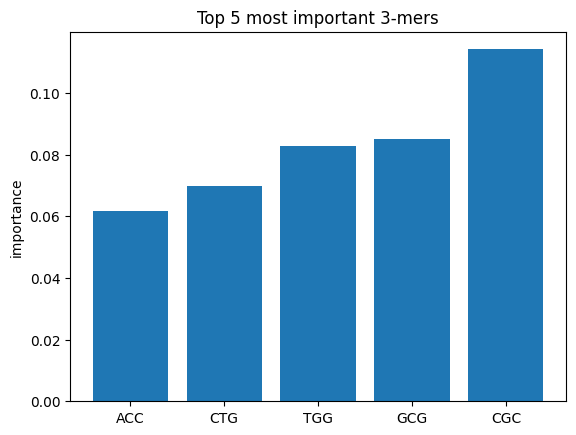

In [36]:
import matplotlib.pyplot as plt

names = [all_kmers[i] for i in top]
scores = [model.feature_importances_[i] for i in top]

plt.bar(names, scores)
plt.title("Top 5 most important 3-mers")
plt.ylabel("importance")
plt.show()